# Structural T1 preprocessing walkthrough

Run cells from top to bottom to preprocess one scan with the **same pipeline functions and configuration as the batch CLI**, then inspect each saved stage independently. Native-space and MNI-space slices have different coordinate systems, so these plots are for stage inspection, not pixel-aligned before/after comparison.

The pipeline retains N4, brain extraction, and affine MNI registration for the Alzheimer’s workflow. Z-score mode applies 0.5th/99.5th percentile clipping within the brain mask before standardization.

Hosted Colab mode explicitly requests CUDA and stops before HD-BET if the kernel cannot see a GPU; local mode uses automatic CPU/GPU selection.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

# Find the repository from the notebook location, current folder, or parent folders.
candidates = [Path.cwd(), *Path.cwd().parents]
candidates += [Path(__file__).resolve().parent, *Path(__file__).resolve().parents] if '__file__' in globals() else []
candidates.append(Path(r'E:\Desktop\git_repos\DG-TCAV'))  # fallback for this checkout; edit if you cloned elsewhere
REPO_ROOT = next((p for p in candidates if (p / 'preprocessing' / 'config.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate the DG-TCAV repository. Start Jupyter in the repo folder or set REPO_ROOT manually.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from preprocessing.config import PipelineConfig
from preprocessing.pipeline import preprocess_mri_scan
INPUT_SCAN = Path(r'E:\Desktop\git_repos\DG-TCAV\data\941_S_6422\Accelerated_Sagittal_MPRAGE.nii.gz')  # Change to your 3D T1 NIfTI
OUTPUT_DIR = REPO_ROOT / 'data/preprocessed_notebook'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert INPUT_SCAN.is_file(), f'Scan not found: {INPUT_SCAN}'
print('Input:', INPUT_SCAN)

Input: E:\Desktop\git_repos\DG-TCAV\data\941_S_6422\Accelerated_Sagittal_MPRAGE.nii.gz


## Configure and run the integrated pipeline

In [2]:
config = PipelineConfig(
    template_path=REPO_ROOT / 'templates/mni152_t1_2mm.nii.gz',
    brain_extractor='hd-bet',  # or 'synthstrip' when installed
    device='cuda' if globals().get('IN_COLAB', False) else 'auto',  # local mode auto-detects CUDA/CPU
    registration='affine',
    disable_tta=False,  # keep HD-BET test-time augmentation enabled for quality
    normalization='zscore',
)
output_path = OUTPUT_DIR / f'{INPUT_SCAN.name.removesuffix(".nii.gz").removesuffix(".nii")}_preprocessed_mni152_2mm.nii.gz'
result = preprocess_mri_scan(
    str(INPUT_SCAN),
    output_path=str(output_path),
    collect_steps=True,  # Keep intermediates in memory for this single-scan review
    config=config,
) 
steps = result.step_volumes 
template_mask_path = config.template_path.with_name('mni152_t1_2mm_brain_mask.nii.gz')
template_mask_data = np.asarray(nib.load(str(template_mask_path)).dataobj) > 0
print(f'QA: {result.qa_message}; volume={result.brain_volume_liters:.3f} L; Dice={result.template_dice:.3f}; time={result.elapsed_sec:.1f}s')
print('Saved output:', output_path) 

[Accelerated_Sagittal_MPRAGE] Stage 1/5: Loading & canonical RAS+ orientation.
[Accelerated_Sagittal_MPRAGE] Stage 2/5: N4ITK bias field correction.
[Accelerated_Sagittal_MPRAGE] Stage 3/5: Deep learning skull-stripping (hd-bet).
HD-BET starting: device=cpu, TTA=off; elapsed time includes process startup and any first-run weight download.
HD-BET finished in 667.0s.
[Accelerated_Sagittal_MPRAGE] Stage 4/5: Stabilized affine registration to MNI152.
[Accelerated_Sagittal_MPRAGE] Stage 5/5: Intensity normalization (zscore).
[Accelerated_Sagittal_MPRAGE] QA Status: VALID | Volume: 1.04L (129380 voxels) | Dice: 0.709
QA: VALID; volume=1.035 L; Dice=0.709; time=720.5s
Saved output: e:\Desktop\git_repos\DG-TCAV\data\preprocessed_notebook\Accelerated_Sagittal_MPRAGE_preprocessed_mni152_2mm.nii.gz


Each cell below plots the middle axial, coronal, and sagittal slices of that stage’s own grid. Native and MNI views are not pixel-aligned. In the registered view, cyan is the subject mask and dashed magenta is the MNI template mask; substantial contour mismatch deserves review.


In [3]:
def show_stage(key, title, mask_key=None, show_template=False):
    volume = np.asarray(steps[key])
    i, j, k = (n // 2 for n in volume.shape)
    planes = [volume[:, :, k].T, volume[:, j, :].T, volume[i, :, :].T]
    plane_titles = ['Axial', 'Coronal', 'Sagittal']
    mask = np.asarray(steps[mask_key], dtype=bool) if mask_key else None
    mask_planes = ([mask[:, :, k].T, mask[:, j, :].T, mask[i, :, :].T] if mask is not None else [None] * 3)
    ref_planes = ([template_mask_data[:, :, k].T, template_mask_data[:, j, :].T, template_mask_data[i, :, :].T] if show_template else [None] * 3)
    values = volume[mask] if mask is not None and mask.any() else volume[np.isfinite(volume)]
    lo, hi = np.percentile(values, (1, 99)) if values.size else (0, 1)
    if hi <= lo:
        hi = lo + 1
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    fig.suptitle(f'{title} | shape={volume.shape}')
    for ax, plane, plane_mask, ref_plane, label in zip(axes, planes, mask_planes, ref_planes, plane_titles):
        cmap = plt.get_cmap('gray').copy()
        shown = np.ma.masked_where(~plane_mask, plane) if plane_mask is not None else plane
        if plane_mask is not None:
            cmap.set_bad('black')  # zero-valued background is not brain tissue
        ax.imshow(shown, cmap=cmap, origin='lower', vmin=lo, vmax=hi)
        if plane_mask is not None and plane_mask.any():
            ax.contour(plane_mask, levels=[0.5], colors=['cyan'], linewidths=0.7)
        if ref_plane is not None:
            ax.contour(ref_plane, levels=[0.5], colors=['magenta'], linewidths=0.7, linestyles='dashed')
        ax.set_title(label)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## 1. Raw input

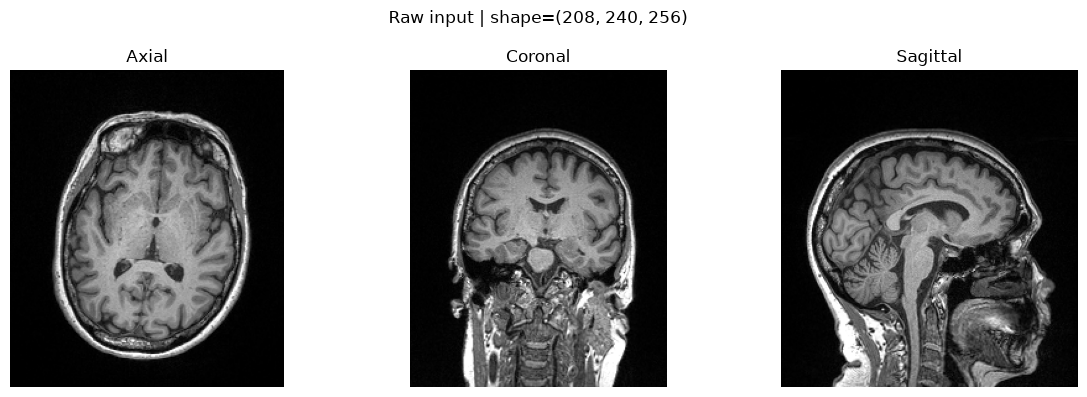

In [4]:
show_stage('0_raw', 'Raw input')

## 2. Canonical RAS orientation

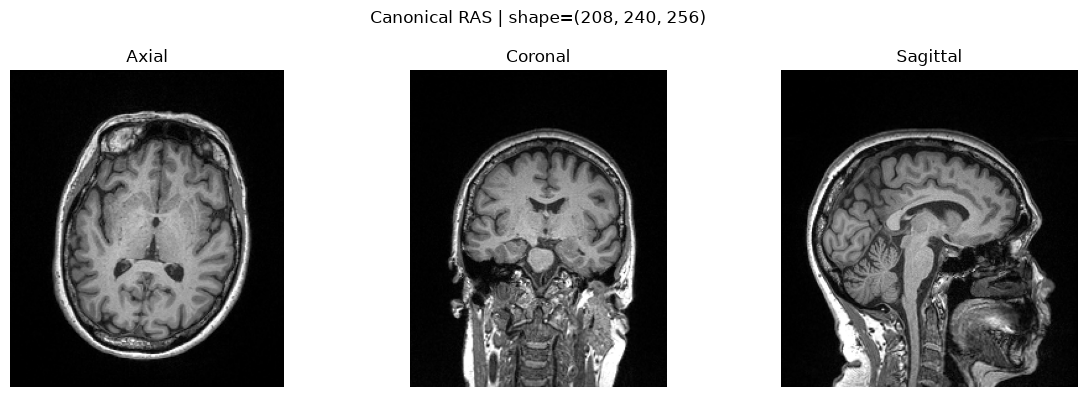

In [5]:
show_stage('1_ras', 'Canonical RAS')

## 3. N4 bias correction

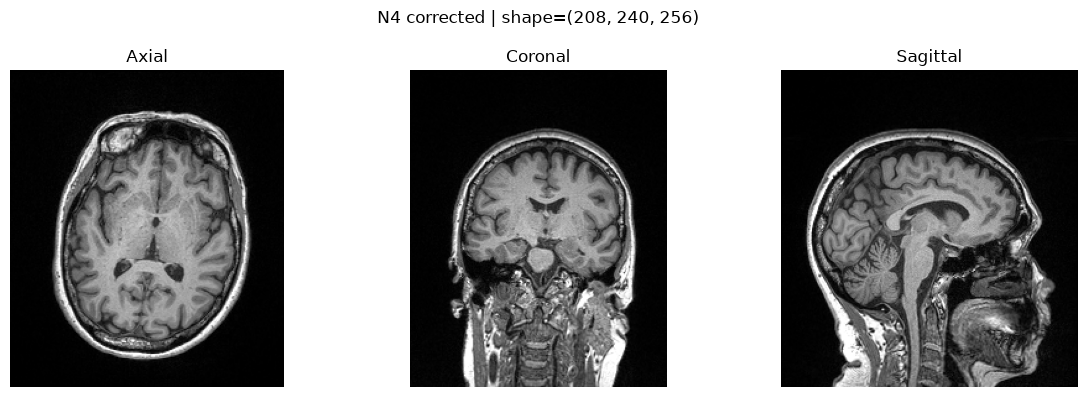

In [6]:
show_stage('2_n4', 'N4 corrected')

## 4. Brain extraction

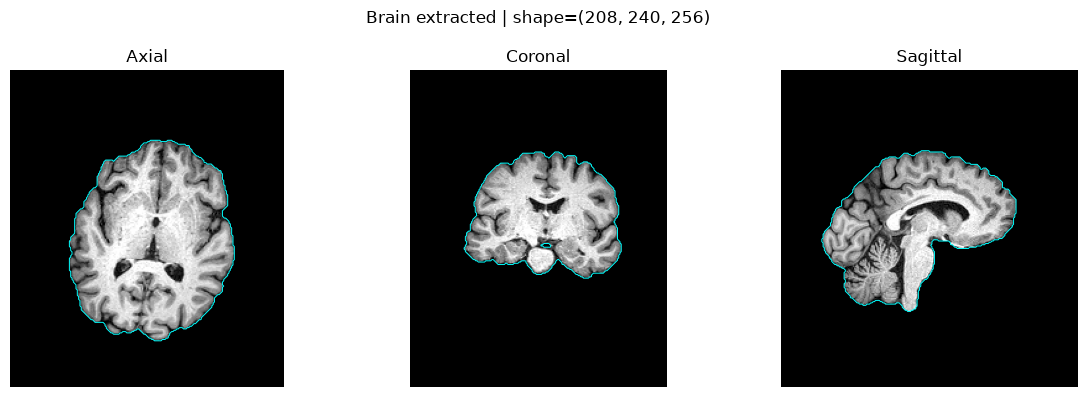

In [7]:
show_stage('3_stripped', 'Brain extracted', '3_mask')

## 5. Affine registration to MNI152

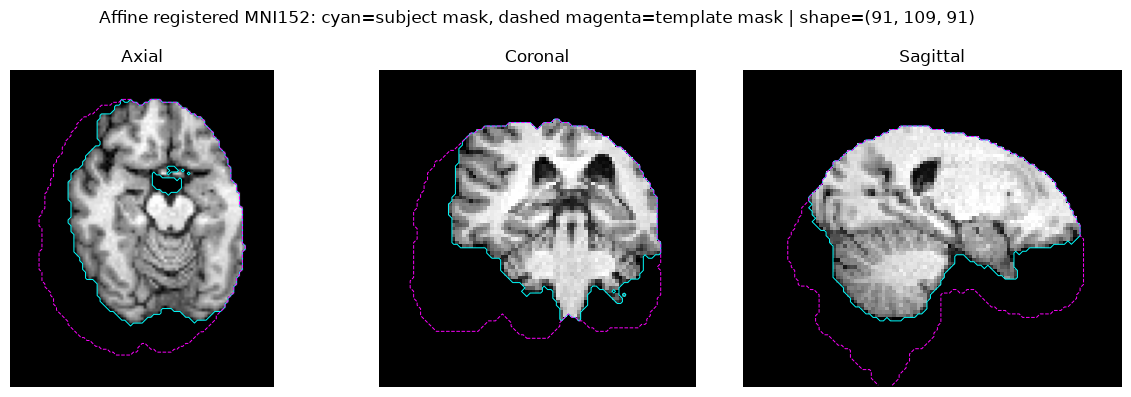

In [8]:
show_stage('4_registered', 'Affine registered MNI152: cyan=subject mask, dashed magenta=template mask', '4_mask', show_template=True)


## 6. Clipped and normalized output

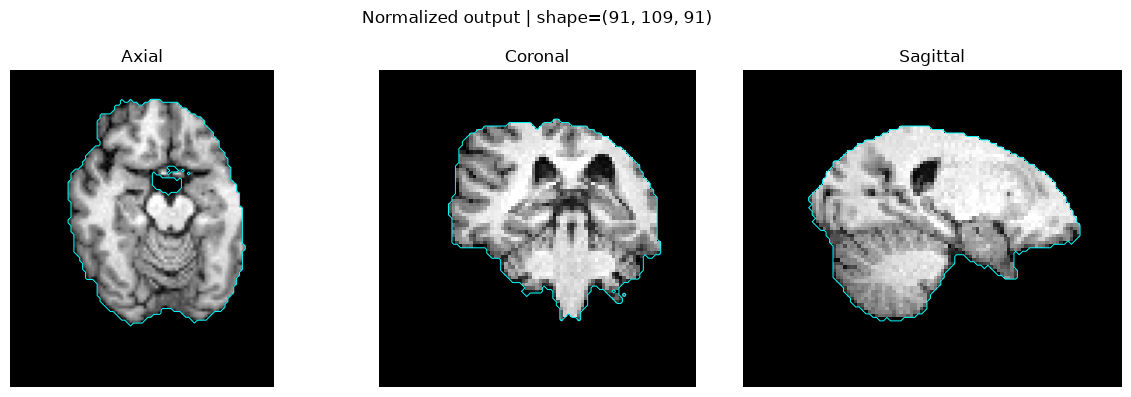

In [9]:
show_stage('5_normalized', 'Normalized output', '4_mask')

## Output geometry and QA summary

In [10]:
saved = nib.load(str(output_path))
print('QA passed:', result.qa_passed)
print('QA message:', result.qa_message)
print('Output shape:', saved.shape)
print('Output spacing (mm):', saved.header.get_zooms()[:3])
print('Foreground mean/std:', result.brain_mean, result.brain_std)

QA passed: True
QA message: VALID
Output shape: (91, 109, 91)
Output spacing (mm): (np.float32(2.0), np.float32(2.0), np.float32(2.0))
Foreground mean/std: -9.623722263540913e-08 1.0
